<a href="https://colab.research.google.com/github/Sendenser/Penguins_Project/blob/main/penguin_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Penguin Species Classifier: Training and Inference Walkthrough

**What you'll see in this notebook**

1. The data: real Palmer Penguins measurements
2. Training a small PyTorch MLP from scratch, with the loss and accuracy curves updating live
3. An honest test-set evaluation against a baseline
4. Inference on real input: **one success case** and **one honest failure case**
5. A "try your own penguin" cell

Code and report: https://github.com/Sendenser/Penguins_Project

*How to use it for a recorded demo:* run the cells one at a time (Shift+Enter) and read the text cells aloud as the narration. Every number in the narration is printed by the code, so nothing is pre-written.

## 1. Setup

**Narration:** "I'll start by importing the libraries and fixing the random seed so that anyone who reruns this notebook gets the same split and the same trained model. The network is tiny, so I'm using the CPU. A GPU wouldn't help here, and the CPU keeps the results reproducible."

In [1]:
import random, time, collections
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, random_split
from sklearn.preprocessing import StandardScaler
from IPython.display import clear_output, display

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("PyTorch", torch.__version__, "| running on CPU")

PyTorch 2.11.0+cpu | running on CPU


## 2. The data

**Narration:** "The task is to predict a penguin's species, Adelie, Chinstrap or Gentoo, from four body measurements plus which island it lives on and its sex. This is real field data from Palmer Station in Antarctica. It comes with missing values, so the first thing I do is drop incomplete rows and check how many species examples are left."

In [2]:
raw = sns.load_dataset("penguins")
df = raw.dropna().reset_index(drop=True)
print(f"{len(raw)} rows -> {len(df)} after dropping rows with missing values\n")
display(df.head())
print("\nExamples per species:")
print(df["species"].value_counts().to_string())

344 rows -> 333 after dropping rows with missing values



,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male



Examples per species:
species
Adelie       146
Gentoo       119
Chinstrap     68


**Narration:** "Next I split the data 60/20/20 into train, validation and test sets. The numeric features are standardized, and the scaler is fit on the **training set only**. If I fit it on everything, information from the test set would leak into training. Categorical columns, island and sex, are one-hot encoded. The test set stays untouched until the very end."

In [3]:
NUM_COLS = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
CAT_COLS = ["island", "sex"]

classes = sorted(df["species"].unique())
y = torch.tensor([classes.index(s) for s in df["species"]])
X_df = pd.concat([df[NUM_COLS], pd.get_dummies(df[CAT_COLS], dtype=float)], axis=1)
feature_names = list(X_df.columns)
full = TensorDataset(torch.tensor(X_df.values, dtype=torch.float32), y)

n_test = len(full) // 5
n_val = len(full) // 5
n_train = len(full) - n_val - n_test
g = torch.Generator().manual_seed(SEED)
tr, va, te = random_split(full, [n_train, n_val, n_test], generator=g)
idx = {"train": list(tr.indices), "val": list(va.indices), "test": list(te.indices)}

Xraw = full.tensors[0]
scaler = StandardScaler().fit(Xraw[idx["train"]][:, :4].numpy())   # fit on TRAIN only

def make(split):
    xb = Xraw[idx[split]].clone()
    xb[:, :4] = torch.tensor(scaler.transform(xb[:, :4].numpy()), dtype=torch.float32)
    return TensorDataset(xb, y[idx[split]])

sets = {k: make(k) for k in idx}
train_loader = DataLoader(sets["train"], batch_size=16, shuffle=True)
val_loader = DataLoader(sets["val"], batch_size=16)
test_loader = DataLoader(sets["test"], batch_size=16)

print(f"features ({len(feature_names)}): {feature_names}")
print(f"train={n_train}  val={n_val}  test={n_test}")

features (9): ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'island_Biscoe', 'island_Dream', 'island_Torgersen', 'sex_Female', 'sex_Male']
train=201  val=66  test=66


## 3. The model

**Narration:** "The model is a small multilayer perceptron: two hidden layers of 32 units, ReLU activations, and dropout after the first layer for regularization. The output is three logits, one per species. It has under fifteen hundred parameters, and it starts from random weights. Nothing is pretrained."

In [4]:
class MLP(nn.Module):
    def __init__(self, in_features, n_classes, hidden=32, p_drop=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden), nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_classes))
    def forward(self, x):
        return self.net(x)

model = MLP(len(feature_names), len(classes))
print(model)
print(f"\ntrainable parameters: {sum(p.numel() for p in model.parameters()):,}")

MLP(
  (net): Sequential(
    (0): Linear(in_features=9, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=3, bias=True)
  )
)

trainable parameters: 1,475


## 4. Training, live

**Narration:** "Now the training loop. For each batch I run the forward pass, compute cross-entropy loss, clear old gradients, backpropagate, and let the Adam optimizer update the weights. After every epoch I measure loss and accuracy on both the training set and the validation set. I'm watching for the two curves to separate, because that gap is what overfitting looks like."

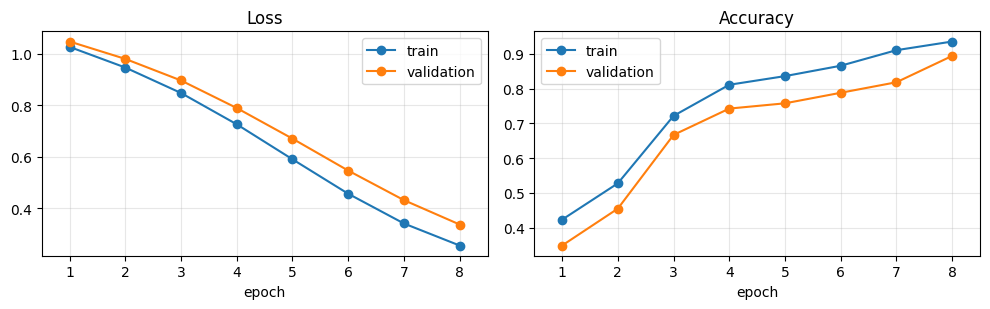

epoch 8/8  train_loss=0.255 acc=93.5%  |  val_loss=0.336 acc=89.4%


In [5]:
EPOCHS, LR, WD = 8, 1e-3, 1e-4
PAUSE = 0.6        # seconds between epochs so the live plot is watchable; set 0 for speed

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)

@torch.no_grad()
def evaluate(loader):
    model.eval()
    L, Y = [], []
    for x, yy in loader:
        L.append(model(x)); Y.append(yy)
    L, Y = torch.cat(L), torch.cat(Y)
    return loss_fn(L, Y).item(), (L.argmax(-1) == Y).float().mean().item()

hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
for epoch in range(1, EPOCHS + 1):
    model.train()
    for x, yy in train_loader:
        loss = loss_fn(model(x), yy)      # forward + loss
        optimizer.zero_grad()             # clear old gradients
        loss.backward()                   # backprop
        optimizer.step()                  # update weights
    tl, ta = evaluate(train_loader)
    vl, va_ = evaluate(val_loader)
    for k, v in zip(hist, (tl, vl, ta, va_)):
        hist[k].append(v)

    clear_output(wait=True)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.2))
    ep = range(1, epoch + 1)
    a1.plot(ep, hist["train_loss"], "-o", label="train"); a1.plot(ep, hist["val_loss"], "-o", label="validation")
    a1.set(title="Loss", xlabel="epoch", xlim=(0.5, EPOCHS + 0.5)); a1.legend(); a1.grid(alpha=.3)
    a2.plot(ep, hist["train_acc"], "-o", label="train"); a2.plot(ep, hist["val_acc"], "-o", label="validation")
    a2.set(title="Accuracy", xlabel="epoch", xlim=(0.5, EPOCHS + 0.5)); a2.legend(); a2.grid(alpha=.3)
    plt.tight_layout(); plt.show()
    print(f"epoch {epoch}/{EPOCHS}  train_loss={tl:.3f} acc={ta:.1%}  |  val_loss={vl:.3f} acc={va_:.1%}")
    time.sleep(PAUSE)

**Narration:** "Both curves move together and the gap between them is small, so the model isn't memorizing the training set. I'll be honest about one thing: if the validation loss is still dropping at epoch 8, as it may be here, the model is slightly under-trained rather than over-fitted. More epochs would probably help a little. I'm keeping 8 so the demo stays quick."

## 5. Evaluation on the held-out test set

**Narration:** "Now I touch the test set for the first time, and I won't tune anything after seeing this number. I compare against a majority-class baseline, which is what you'd get by always guessing the most common species. If the model can't beat that, it has learned nothing."

Majority-class baseline (always 'Adelie'): 57.6%
MLP test accuracy: 90.9%   (6 wrong out of 66)

Note: with only 66 test penguins, one extra mistake moves accuracy by 1.5 points.


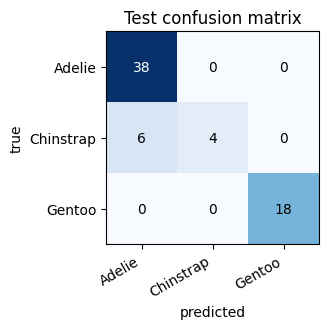

In [6]:
@torch.no_grad()
def predict_split(split):
    model.eval()
    x, yy = sets[split].tensors
    return torch.softmax(model(x), -1), yy

p_test, y_test = predict_split("test")
test_acc = (p_test.argmax(-1) == y_test).float().mean().item()
maj = collections.Counter(sets["train"].tensors[1].tolist()).most_common(1)[0][0]
maj_acc = (y_test == maj).float().mean().item()
n_err = int((p_test.argmax(-1) != y_test).sum())

print(f"Majority-class baseline (always '{classes[maj]}'): {maj_acc:.1%}")
print(f"MLP test accuracy: {test_acc:.1%}   ({n_err} wrong out of {len(y_test)})")
print(f"\nNote: with only {len(y_test)} test penguins, one extra mistake moves accuracy by {100/len(y_test):.1f} points.")

cm = np.zeros((3, 3), int)
for t, p in zip(y_test.tolist(), p_test.argmax(-1).tolist()):
    cm[t, p] += 1
fig, ax = plt.subplots(figsize=(4, 3.4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3)); ax.set_xticklabels(classes, rotation=30, ha="right")
ax.set_yticks(range(3)); ax.set_yticklabels(classes)
ax.set(xlabel="predicted", ylabel="true", title="Test confusion matrix")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.show()

## 6. Inference on real input

**Narration:** "So far I've only evaluated pre-processed tensors. A trained model is only useful if I can hand it a *raw* penguin, with measurements in millimetres and an island name, and get an answer. This function does that. It builds the feature vector in the same column order as training, applies the **saved training scaler**, and returns a probability for each species."

In [7]:



def predict_penguin(island, sex, bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g):
    row = dict.fromkeys(feature_names, 0.0)
    row.update(bill_length_mm=bill_length_mm, bill_depth_mm=bill_depth_mm,
               flipper_length_mm=flipper_length_mm, body_mass_g=body_mass_g)
    for key in (f"island_{island}", f"sex_{sex}"):
        if key not in row:
            raise ValueError(f"unknown category {key!r}; valid: {[f for f in feature_names if '_' in f and f[:3] in ('isl','sex')]}")
        row[key] = 1.0
    x = torch.tensor([[row[f] for f in feature_names]], dtype=torch.float32)
    x[:, :4] = torch.tensor(scaler.transform(x[:, :4].numpy()), dtype=torch.float32)
    model.eval()
    with torch.no_grad():
        p = torch.softmax(model(x), -1)[0]
    return {c: float(p[i]) for i, c in enumerate(classes)}

def show(probs, title):
    fig, ax = plt.subplots(figsize=(5.5, 2.2))
    ax.barh(list(probs), list(probs.values()), color=["#2563eb", "#16a34a", "#d97706"])
    ax.set(xlim=(0, 1), xlabel="probability", title=title); ax.invert_yaxis()
    for i, v in enumerate(probs.values()):
        ax.text(min(v + 0.02, 0.85), i, f"{v:.1%}", va="center")
    plt.tight_layout(); plt.show()

### Success case

**Narration:** "For the success case I take a real penguin from the **test set**, one the model never trained on, and feed it in as raw numbers. To be transparent: I'm picking the correct prediction the model was *most* confident about. That makes this a best case, not a typical case. The test accuracy above is the honest summary."

INPUT : {'island': 'Biscoe', 'sex': 'Male', 'bill_length_mm': np.float64(49.8), 'bill_depth_mm': np.float64(15.9), 'flipper_length_mm': np.float64(229.0), 'body_mass_g': np.float64(5950.0)}
TRUE  : Gentoo
MODEL : Gentoo (96.0%)
(sanity check passed: raw-input path gives the same probabilities as the batch evaluation)


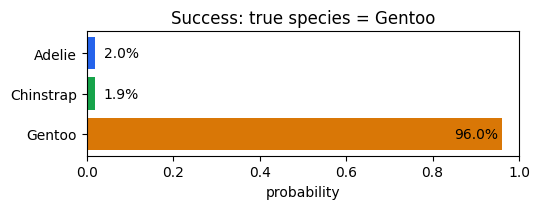

In [8]:
conf, pred = p_test.max(-1)
correct = torch.where(pred == y_test)[0]
best = correct[conf[correct].argmax()].item()
r = df.loc[idx["test"][best]]

inp = dict(island=r["island"], sex=r["sex"], bill_length_mm=r["bill_length_mm"],
           bill_depth_mm=r["bill_depth_mm"], flipper_length_mm=r["flipper_length_mm"],
           body_mass_g=r["body_mass_g"])
print("INPUT :", inp)
probs = predict_penguin(**inp)
print("TRUE  :", r["species"])
print("MODEL :", max(probs, key=probs.get), f"({max(probs.values()):.1%})")
assert np.allclose(list(probs.values()), p_test[best].numpy(), atol=1e-4), "raw-input path disagrees with batch path"
print("(sanity check passed: raw-input path gives the same probabilities as the batch evaluation)")
show(probs, f"Success: true species = {r['species']}")

### Failure case 1: a real misclassification

**Narration:** "Now the part that matters for honesty. I search the validation and test sets for penguins the model got **wrong**, and show the most confident mistake. If the model made no mistakes on those sets, the code says so and shows the closest call instead. A model that is right on a few dozen examples is not a perfect model."

Found 13 misclassified penguin(s) in test+val. Showing the most confident mistake (val set).

INPUT : {'island': 'Dream', 'sex': 'Female', 'bill_length_mm': np.float64(40.9), 'bill_depth_mm': np.float64(16.6), 'flipper_length_mm': np.float64(187.0), 'body_mass_g': np.float64(3200.0)}
TRUE  : Chinstrap
MODEL : Adelie (77.3%)

Distance to class average (standardized units): Chinstrap = 2.11, Adelie = 1.17
-> This penguin really does look more like an average Adelie than an average Chinstrap: an atypical individual.


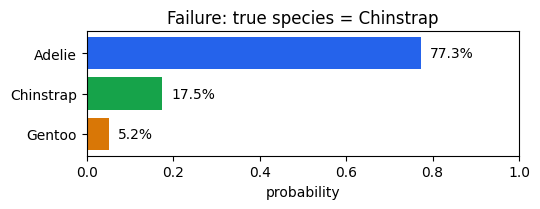

In [9]:
cands = []
for split in ("test", "val"):
    p, yy = predict_split(split)
    for k in torch.where(p.argmax(-1) != yy)[0].tolist():
        cands.append((split, k, p[k], int(yy[k])))

if cands:
    split, k, pk, true_c = max(cands, key=lambda c: c[2].max().item())
    print(f"Found {len(cands)} misclassified penguin(s) in test+val. Showing the most confident mistake ({split} set).\n")
else:
    p, yy = predict_split("test")
    top2 = p.topk(2, dim=-1).values
    k = int((top2[:, 0] - top2[:, 1]).argmin()); split, pk, true_c = "test", p[k], int(yy[k])
    print("No mistakes on the validation or test sets. Showing the closest call (smallest gap between top-2 classes).\n")

r = df.loc[idx[split][k]]
inp = dict(island=r["island"], sex=r["sex"], bill_length_mm=r["bill_length_mm"],
           bill_depth_mm=r["bill_depth_mm"], flipper_length_mm=r["flipper_length_mm"],
           body_mass_g=r["body_mass_g"])
probs = predict_penguin(**inp)
pred_name = max(probs, key=probs.get)
print("INPUT :", inp)
print("TRUE  :", classes[true_c])
print("MODEL :", pred_name, f"({probs[pred_name]:.1%})")

# why? compare to class averages in standardized units
mu = {c: Xraw[[i for i in idx['train'] if y[i] == ci]][:, :4].numpy().mean(0) for ci, c in enumerate(classes)}
sd = Xraw[idx["train"]][:, :4].numpy().std(0)
x = np.array([inp[c] for c in NUM_COLS])
d = {c: float(np.sqrt((((x - mu[c]) / sd) ** 2).sum())) for c in (classes[true_c], pred_name)}
print(f"\nDistance to class average (standardized units): {classes[true_c]} = {d[classes[true_c]]:.2f}, {pred_name} = {d[pred_name]:.2f}")
if pred_name != classes[true_c]:
    if d[pred_name] < d[classes[true_c]]:
        print(f"-> This penguin really does look more like an average {pred_name} than an average {classes[true_c]}: an atypical individual.")
    else:
        print("-> It is still closer to its own class average, so the mistake is not explained by simple distance. The learned decision boundary is the more likely cause.")
    if probs[pred_name] >= 0.8:
        print("-> The model was CONFIDENTLY wrong: its probability output gave no warning.")
show(probs, f"Failure: true species = {classes[true_c]}")

### Failure case 2: an input the model should not trust

**Narration:** "There is a second, more fundamental failure, and I can force it. I'll give the model an input that is **not a plausible penguin at all**: a 90-millimetre bill, a 4-millimetre bill depth, and a 12-kilogram body. The correct answer is 'none of the above', but the model only has three outputs, and a softmax always spreads 100 percent of its probability across them. So it has to pick a species."

INPUT: {'island': 'Dream', 'sex': 'Female', 'bill_length_mm': 90.0, 'bill_depth_mm': 4.0, 'flipper_length_mm': 300.0, 'body_mass_g': 12000.0}
MODEL: Gentoo (100.0%)

-> The model is highly confident about an input unlike anything in the training data. High confidence here is NOT evidence of correctness.


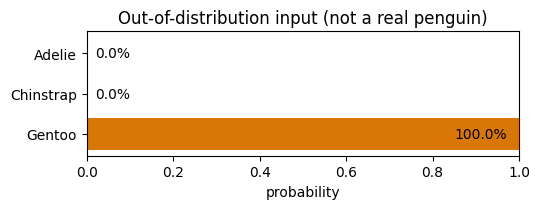

In [10]:
weird = dict(island="Dream", sex="Female", bill_length_mm=90.0, bill_depth_mm=4.0,
             flipper_length_mm=300.0, body_mass_g=12000.0)
probs = predict_penguin(**weird)
top = max(probs, key=probs.get)
print("INPUT:", weird)
print("MODEL:", top, f"({probs[top]:.1%})")
if probs[top] > 0.9:
    print("\n-> The model is highly confident about an input unlike anything in the training data. High confidence here is NOT evidence of correctness.")
else:
    print("\n-> The model is less sure here, but it still must choose one of the three species; it cannot say 'this is not a penguin I know'.")
show(probs, "Out-of-distribution input (not a real penguin)")

## 7. Try your own penguin

**Narration:** "Here is a live cell. Change the values in the form on the right, run it, and the model answers. The model has only seen Palmer Station penguins, so anything far from those measurements is outside what it knows."

Prediction: Adelie (93.8%)


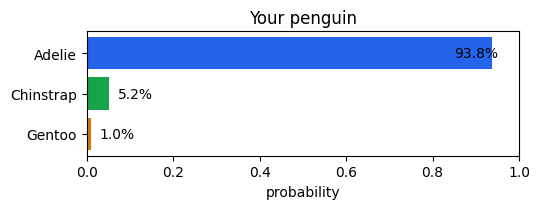

In [11]:
#@title Enter a penguin { run: "auto" }
island = "Torgersen" #@param ["Biscoe", "Dream", "Torgersen"]
sex = "Male" #@param ["Male", "Female"]
bill_length_mm = 39.1 #@param {type:"number"}
bill_depth_mm = 18.7 #@param {type:"number"}
flipper_length_mm = 181 #@param {type:"number"}
body_mass_g = 3750 #@param {type:"number"}

probs = predict_penguin(island, sex, bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g)
top = max(probs, key=probs.get)
print(f"Prediction: {top} ({probs[top]:.1%})")
show(probs, "Your penguin")

## 8. Summary and honest caveats

**Narration:** "To wrap up. I trained a small neural network from scratch, evaluated it once on held-out data, and compared it to a baseline. It handled a typical real penguin well. But I also showed two ways it fails: it can misclassify an atypical penguin, sometimes confidently, and it will confidently classify nonsense input, because a softmax output cannot express 'I don't know'."

In [12]:
print(f"MLP test accuracy:        {test_acc:.1%}  ({len(y_test)} test penguins)")
print(f"Majority-class baseline:  {maj_acc:.1%}")
print(f"Test mistakes:            {n_err}")
print("\nCaveats:")
print(f" - Only {len(y_test)} test examples: one mistake = {100/len(y_test):.1f} points, so treat the exact accuracy as approximate.")
print(" - One random split. A different seed gives a somewhat different number.")
print(" - Trained on 3 islands from one study; no evidence it transfers to other penguin populations.")
print(" - Out-of-range inputs still get a confident answer (see failure case 2).")
torch.save(model.state_dict(), "model.pt")
print("\nSaved trained weights to model.pt")

MLP test accuracy:        90.9%  (66 test penguins)
Majority-class baseline:  57.6%
Test mistakes:            6

Caveats:
 - Only 66 test examples: one mistake = 1.5 points, so treat the exact accuracy as approximate.
 - One random split. A different seed gives a somewhat different number.
 - Trained on 3 islands from one study; no evidence it transfers to other penguin populations.
 - Out-of-range inputs still get a confident answer (see failure case 2).

Saved trained weights to model.pt
